In [1]:
from pytem import TEM
from pygimli.viewer.mpl.overlayimage import underlayBKGMap

The instance is instantiated through the data file name. Instead of the USF files, we chose the xyz data files as it includes all soundings in one go. Whereas the data are in the xyz file, a gex file is exported containing the geometry of the loops, the time gates and the current waveform. If a file with the same name like the xyz file but the ending gex is found, it is read by default. Alternatively, you can specify this file explicitly by `cfg=`.

In [2]:
tem = TEM("sTEM.xyz")
print(tem)

dict_keys(['rxpos', 'txpos', 'tx', 'ty', 'txarea', 'tL', 'vL', 'tH', 'vH', 'timeL', 'timeH'])
set dual mode
ready
TEM profile with 15 soundings
29 times (1.232756e-05-0.002356259)


The file contains 104 soundings with 28 time gates.
In the file, there are also the GPS positions that can be shown:

21/08/26 - 19:57:52 - pyGIMLi - INFO - Retrieving file from geodatenzentrum.de using URL: https://sgx.geodatenzentrum.de/wms_basemapde?service=wms&version=1.3.0&request=GetMap&Layers=de_basemapde_web_raster_farbe&STYLES=default&CRS=EPSG:25833&bbox=319917,5589470,322190,5591737&width=2500&Height=2493&Format=image/png


URLError: <urlopen error [Errno 11001] getaddrinfo failed>

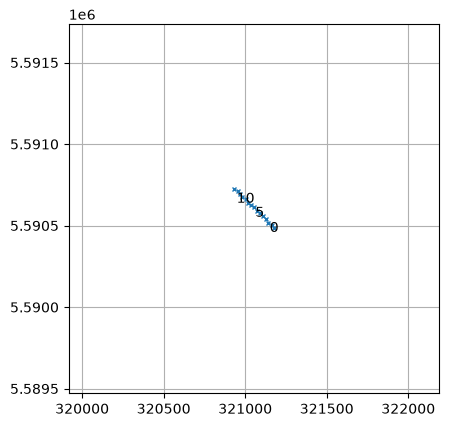

In [3]:
ax = tem.showPositions()
xl = ax.get_xlim()
yl = ax.get_ylim()
pad = 1000
ax.set_xlim(xl[0] - pad, xl[1] + pad)
ax.set_ylim(yl[0] - pad, yl[1] + pad)
underlayBKGMap(ax, utmzone=33)

In [4]:
# tem.filter(nmin=1)
# print(tem)

We can show a single sounding by `showSounding()`

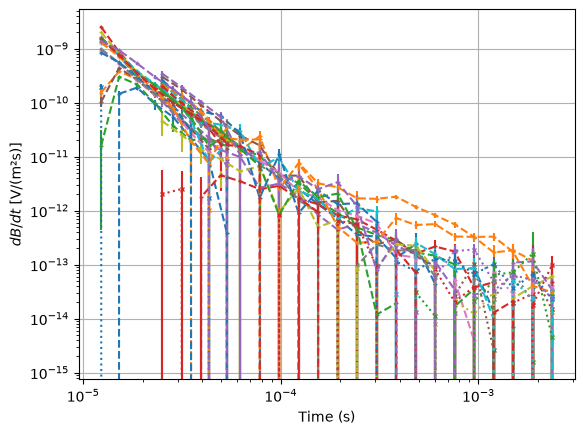

In [5]:
tem.showSoundings();

or, transferred to apparent resistivity

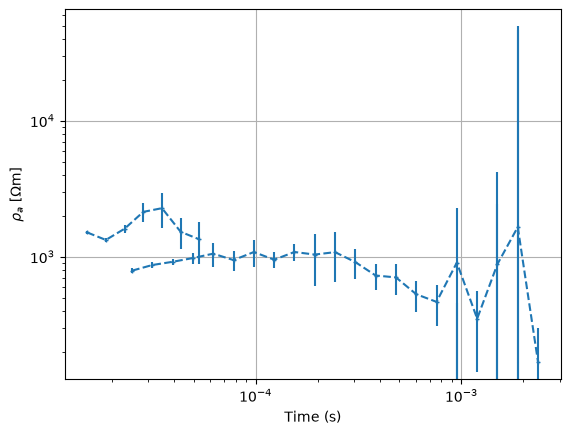

In [6]:
tem.showSounding(n=2, rhoa=True);

To view all data, we can use `showRhoa()`

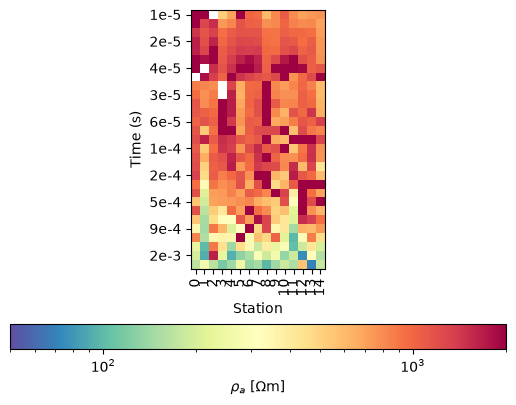

In [7]:
tem.showRhoa(rmin=50, rmax=2000);

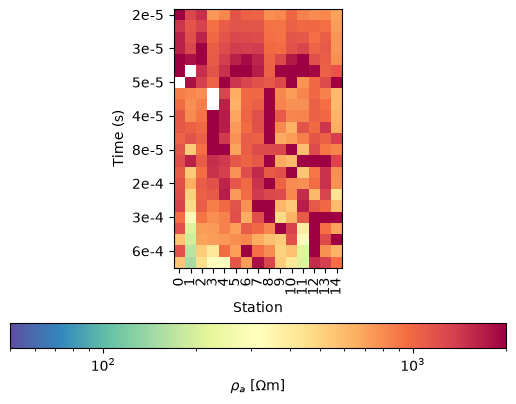

In [9]:
tem.filter(tmin=1.5e-5, tmax=8e-4)#n=[21])
tem.showRhoa(rmin=50, rmax=2000);

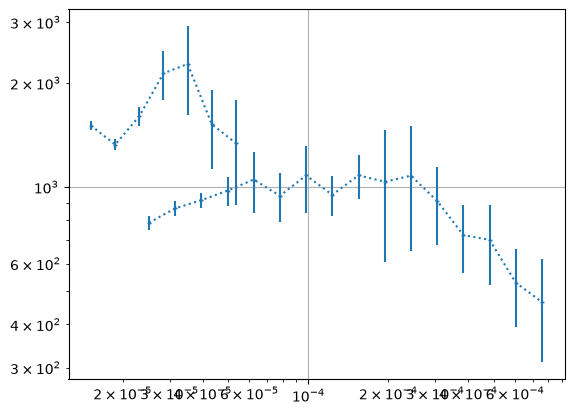

In [48]:
tem.showSounding(n=2, rhoa=True);

21/08/26 - 19:59:50 - pyGIMLi - INFO - Starting inversion.
21/08/26 - 19:59:50 - pyGIMLi - INFO - fop: <pytem.temmodelling.TEMRhoModellingDualMode object at 0x0000024D6A148F90>
21/08/26 - 19:59:50 - pyGIMLi - INFO - Data transformation: Identity transform
21/08/26 - 19:59:50 - pyGIMLi - INFO - Model transformation: Logarithmic transform
21/08/26 - 19:59:50 - pyGIMLi - INFO - min/max (data): 1.0e-13/3.0e-10
21/08/26 - 19:59:50 - pyGIMLi - INFO - min/max (error): 4.42%/62.32%
21/08/26 - 19:59:50 - pyGIMLi - INFO - min/max (start model): 250/250


--------------------------------------------------------------------------------


21/08/26 - 20:00:12 - pyGIMLi - INFO - inv.iter 0 ... chi² = 187790.74


--------------------------------------------------------------------------------
inv.iter 1 ... 

21/08/26 - 20:00:13 - pyGIMLi - INFO - chi² = 23426.77 (dPhi = 87.46%) lam: 20.0


...

--------------------------------------------------------------------------------
inv.iter 6 ... 

21/08/26 - 20:01:51 - pyGIMLi - INFO - chi² =    5.30 (dPhi = 40.11%) lam: 20.0


--------------------------------------------------------------------------------
inv.iter 7 ... 

21/08/26 - 20:02:11 - pyGIMLi - INFO - chi² =    5.26 (dPhi = 0.99%) lam: 20.0


################################################################################
#                Abort criterion reached: dPhi = 0.99 (< 2.0%)                 #
################################################################################


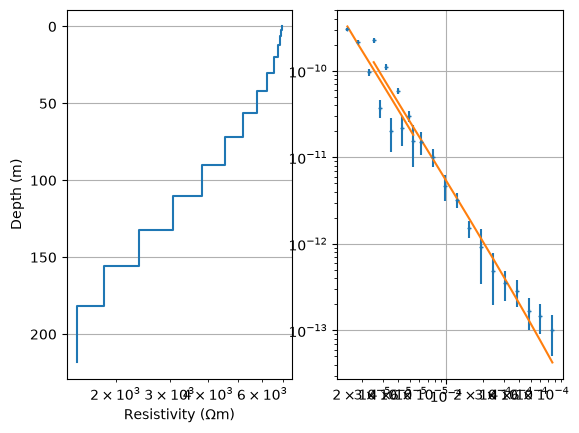

In [10]:
tem.invertSounding(2);

and see the change from the resistive (>100$\Omega$m) top layer to the conductive layer below (cf. Fig. 4c).
For inverting all soundings subsequently, we use 

18/03/26 - 21:42:16 - pyGIMLi - INFO - Starting inversion.


fop: <stem.sTEMRhoModelling object at 0x0000019AC2F31B70>
Data transformation: Identity transform
Model transformation: Logarithmic transform
min/max (data): 1.3e-12/1.3e-07
min/max (error): 3%/8.93%
min/max (start model): 250/250
--------------------------------------------------------------------------------
inv.iter 0 ... chi² =  518.46
--------------------------------------------------------------------------------
inv.iter 1 ... chi² =  279.40 (dPhi = 45.91%) lam: 20.0
--------------------------------------------------------------------------------
inv.iter 2 ... chi² =   16.89 (dPhi = 92.38%) lam: 20.0
--------------------------------------------------------------------------------
inv.iter 3 ... chi² =    3.57 (dPhi = 75.11%) lam: 20.0
--------------------------------------------------------------------------------
inv.iter 4 ... chi² =    0.58 (dPhi = 62.69%) lam: 20.0


################################################################################
#                  Abort cr

18/03/26 - 21:42:39 - pyGIMLi - INFO - 1: chi2=0.34 (2 iter)


18/03/26 - 21:42:43 - pyGIMLi - INFO - 2: chi2=0.45 (2 iter)


18/03/26 - 21:42:48 - pyGIMLi - INFO - 3: chi2=0.63 (2 iter)


...

18/03/26 - 21:43:02 - pyGIMLi - INFO - 5: chi2=1.17 (3 iter)
18/03/26 - 21:43:16 - pyGIMLi - INFO - 6: chi2=1.79 (4 iter)
18/03/26 - 21:43:25 - pyGIMLi - INFO - 7: chi2=2.45 (3 iter)
18/03/26 - 21:43:34 - pyGIMLi - INFO - 8: chi2=2.52 (3 iter)
18/03/26 - 21:43:38 - pyGIMLi - INFO - 9: chi2=0.97 (2 iter)


18/03/26 - 21:43:48 - pyGIMLi - INFO - 10: chi2=3.03 (3 iter)
18/03/26 - 21:44:02 - pyGIMLi - INFO - 11: chi2=2.32 (4 iter)
18/03/26 - 21:44:15 - pyGIMLi - INFO - 12: chi2=1.92 (4 iter)
18/03/26 - 21:44:25 - pyGIMLi - INFO - 13: chi2=1.16 (3 iter)
18/03/26 - 21:44:34 - pyGIMLi - INFO - 14: chi2=0.87 (3 iter)


18/03/26 - 21:44:35 - pyGIMLi - INFO - 15: chi2=0.80 (1 iter)


18/03/26 - 21:44:49 - pyGIMLi - INFO - 16: chi2=1.42 (4 iter)
18/03/26 - 21:44:50 - pyGIMLi - INFO - 17: chi2=0.63 (1 iter)


18/03/26 - 21:45:15 - pyGIMLi - INFO - 18: chi2=0.83 (6 iter)


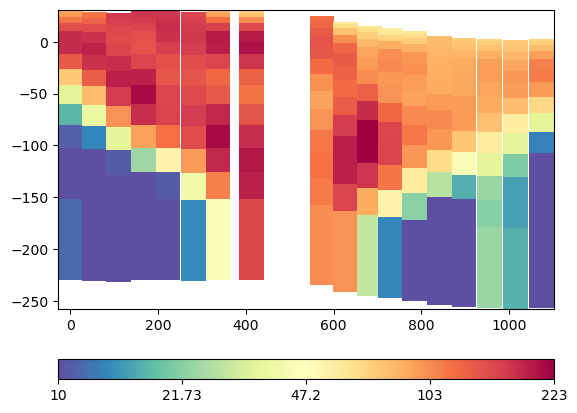

In [20]:
tem.invertAll();

By default, the elevation is extracted and the profile distance is computed by summing the distances.
By calling `showResults(usepos='x')`, one can also use Easting or Northing (`usepos='y'`) for display or `usepos=False` for not using any position. You can also specify the color map and color range.

<Axes: >

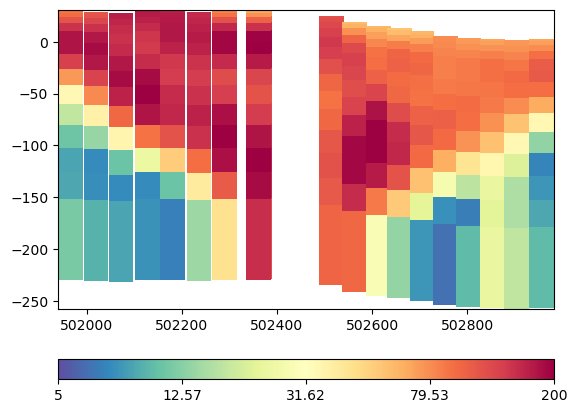

In [24]:
tem.showResults(cMin=5, cMax=200, cMap="Spectral_r", usepos='x')